# DeepInsight

In [125]:
from pyDeepInsight import ImageTransformer
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.manifold import TSNE
import pandas as pd
import numpy as np

## Data preprocessing
Read, normalize data and encode classes

In [126]:
# X, y = load_dataset("dataset/covid/dataset_nuevo_corregido.csv")
import pandas as pd

# Load the CSV file
df = pd.read_csv("../dataset/covid/dataset_nuevo_corregido.csv")

# Assuming your target label column is named "Label"
X = df.drop("Risk_Label", axis=1).drop("Risk", axis=1)
y = df["Risk_Label"]

In [127]:
X.shape

(100297, 11)

In [128]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [129]:
# ln = Norm2Scaler()
# X_train_norm = ln.fit_transform(X_train)
# X_test_norm = ln.transform(X_test)
scaler = MinMaxScaler(feature_range=(0, 1))
X_train_norm = scaler.fit_transform(X_train)
X_test_norm = scaler.transform(X_test)

In [130]:
X_train_norm

array([[0.08256343, 0.17637363, 0.09109109, ..., 0.        , 1.        ,
        1.        ],
       [0.10544068, 0.04615385, 0.00500501, ..., 0.        , 0.        ,
        0.        ],
       [0.00190644, 0.23076923, 0.01301301, ..., 1.        , 0.        ,
        1.        ],
       ...,
       [0.17876521, 0.00549451, 0.004004  , ..., 0.        , 0.        ,
        0.        ],
       [0.0788972 , 0.        , 0.00930931, ..., 0.        , 0.        ,
        1.        ],
       [0.10368089, 0.        , 0.0031031 , ..., 0.        , 0.        ,
        0.        ]])

In [131]:
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
num_classes = np.unique(y_train_enc).size

In [132]:
distance_metric = 'cosine'
reducer = TSNE(
    n_components=2,
    metric=distance_metric,
    init='random',
    learning_rate='auto',
    perplexity=3,
    n_jobs=-1
)

In [133]:
image_size = (6, 6)
it = ImageTransformer(
    feature_extractor=reducer, 
    pixels=image_size,
    n_channels=1 
)

Train image transformer on training data and transform training and testing sets. Values should be between 0 and 1.

c:\Python312\Lib\site-packages\pyDeepInsight\transformer.py:130: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(


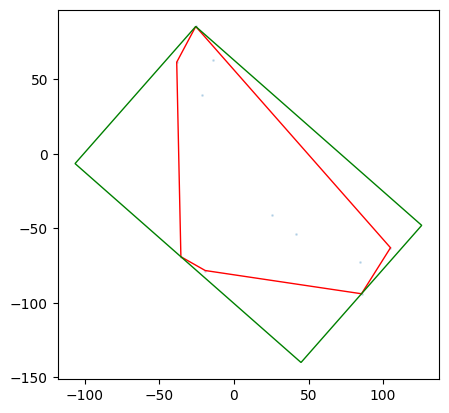

In [134]:
it.fit(X_train_norm, y=y_train, plot=True)
X_train_img = it.transform(X_train_norm)
X_test_img = it.transform(X_test_norm)

The feature density matrix can be extracted from the trained transformer in order to view overall feature overlap.

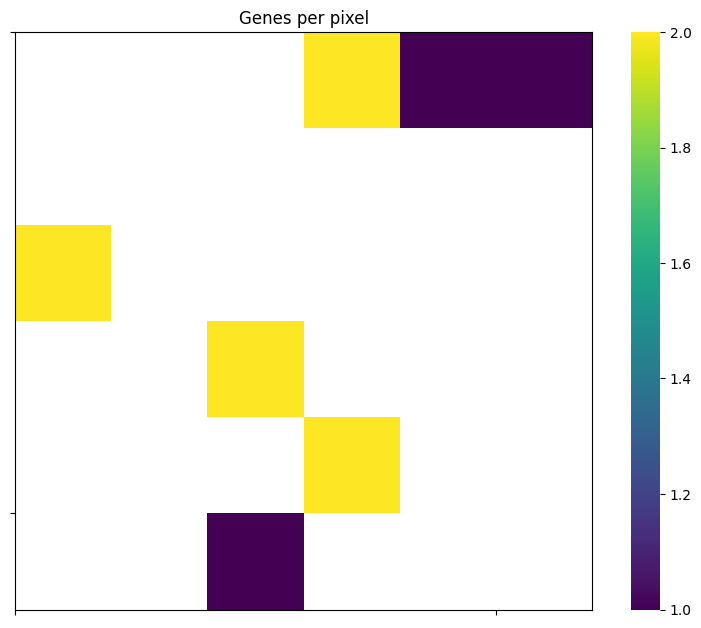

In [135]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

fdm = it.feature_density_matrix(n_channel=0)
fdm[fdm == 0] = np.nan

plt.figure(figsize=(10, 7.5))

ax = sns.heatmap(fdm, cmap="viridis", linewidths=0., 
                 linecolor="lightgrey", square=True)
ax.xaxis.set_major_locator(ticker.MultipleLocator(5))
ax.yaxis.set_major_locator(ticker.MultipleLocator(5))
for _, spine in ax.spines.items():
    spine.set_visible(True)
_ = plt.title("Genes per pixel")

In [136]:

mask_train = y_train != "Extremely High"
X_train_img = X_train_img[mask_train.values]  # Convert the boolean mask to a NumPy array if necessary
y_train = y_train[mask_train]
 
mask_test = y_test != "Extremely High"
X_test_img = X_test_img[mask_test.values]
y_test = y_test[mask_test]

print(np.unique(y_train, return_counts=True))

(array(['High', 'Low', 'Moderate', 'Very High'], dtype=object), array([21894, 13854, 38468,  6003], dtype=int64))


Plots for the image matrices first six samples of the training set.

Labels distribution: (array(['High', 'Low', 'Moderate', 'Very High'], dtype=object), array([21894, 13854, 38468,  6003], dtype=int64))
Class 0, first 5 indices: []
Class 1, first 5 indices: []
Selected indices with labels: []


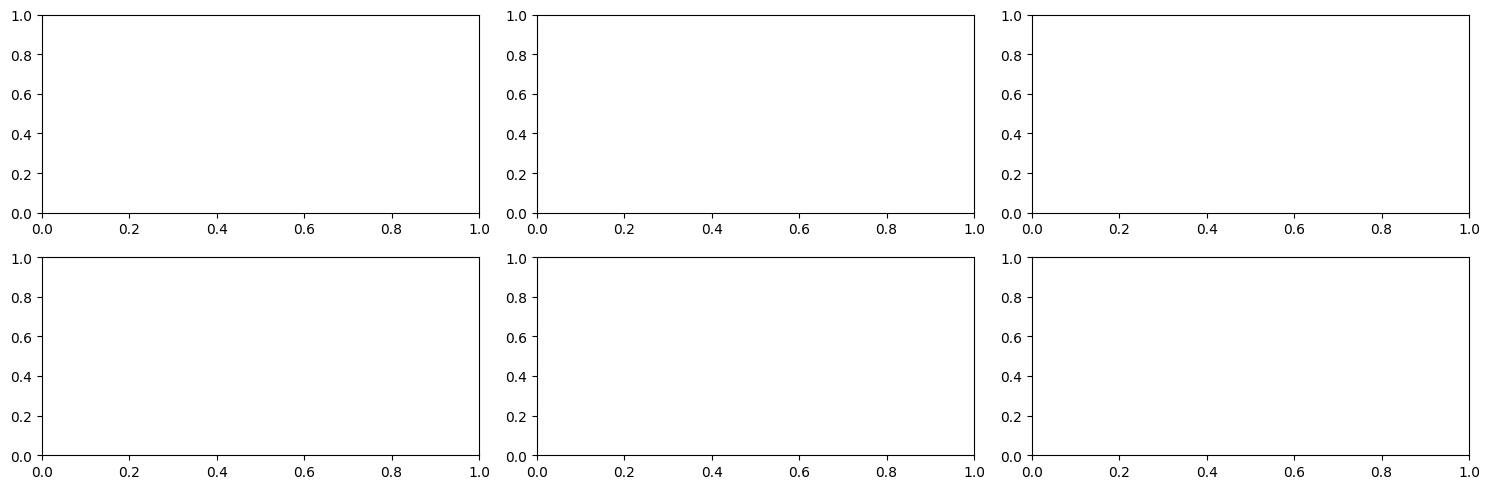

In [137]:
import numpy as np
import matplotlib.pyplot as plt
import random

print("Labels distribution:", np.unique(y_train, return_counts=True))

indices_class_0 = [i for i, lbl in enumerate(y_train) if lbl == 0]
indices_class_1 = [i for i, lbl in enumerate(y_train) if lbl == 1]

random.shuffle(indices_class_0)
random.shuffle(indices_class_1)

print("Class 0, first 5 indices:", indices_class_0[:5])
print("Class 1, first 5 indices:", indices_class_1[:5])

selected_indices = indices_class_0[:3] + indices_class_1[:3]
print("Selected indices with labels:", [(i, y_train.iloc[i]) for i in selected_indices])


fig, ax = plt.subplots(2, 3, figsize=(15, 5))
ax = ax.ravel()

for j, i in enumerate(selected_indices):
    img = np.squeeze(X_train_img[i], axis=0)
    ax[j].imshow(img)
    ax[j].set_title(f"Train[{i}] - class '{y_train.iloc[i]}'")
    ax[j].axis('off')

plt.tight_layout()
plt.show()

Plots for the image matrices first six samples of the test set.

Labels distribution: (array(['High', 'Low', 'Moderate', 'Very High'], dtype=object), array([5346, 3464, 9792, 1454], dtype=int64))
Class 0, first 5 indices: []
Class 1, first 5 indices: []
Selected indices with labels: []


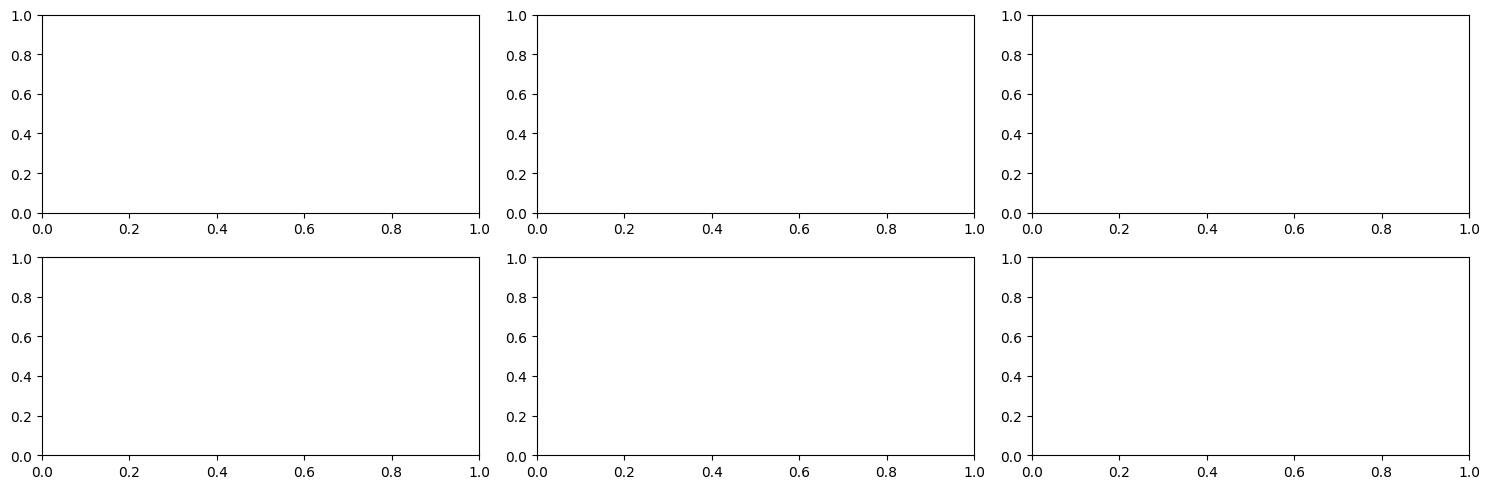

In [138]:
import numpy as np
import matplotlib.pyplot as plt
import random

print("Labels distribution:", np.unique(y_test, return_counts=True))

indices_class_0 = [i for i, lbl in enumerate(y_test) if lbl == 0]
indices_class_1 = [i for i, lbl in enumerate(y_test) if lbl == 1]

random.shuffle(indices_class_0)
random.shuffle(indices_class_1)

print("Class 0, first 5 indices:", indices_class_0[:5])
print("Class 1, first 5 indices:", indices_class_1[:5])

selected_indices = indices_class_0[:3] + indices_class_1[:3]
print("Selected indices with labels:", [(i, y_test.iloc[i]) for i in selected_indices])


fig, ax = plt.subplots(2, 3, figsize=(15, 5))
ax = ax.ravel()

for j, i in enumerate(selected_indices):
    img = np.squeeze(X_test_img[i], axis=0)
    ax[j].imshow(img)
    ax[j].set_title(f"test[{i}] - class '{y_test.iloc[i]}'")
    ax[j].axis('off')

plt.tight_layout()
plt.show()

## Fitting a CNN model

In [139]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torch.utils.data import TensorDataset, DataLoader
import torch.optim as optim
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

In [140]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=8):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)  # Output size: 16x15x15
        self.dropout1 = nn.Dropout(0.25)  # Dropout added for regularization
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)  # Output size: 32x7x7
        self.dropout2 = nn.Dropout(0.25)  # Another dropout layer for regularization
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.dropout1(x)
        x = self.pool(torch.relu(self.conv2(x)))
        x = self.dropout2(x)
        # Dynamically calculate the correct size
        size = x.size(1) * x.size(2) * x.size(3)
        x = x.view(x.size(0), -1)
        if self.fc1.in_features != size:
            self.fc1 = nn.Linear(size, 128).to(x.device)  # Adjust the layer dynamically
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [141]:
from sklearn.preprocessing import LabelEncoder
from collections import Counter
# from sklearn.model_selection import train_test_split
import numpy as np


le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
num_classes = np.unique(y_train_enc).size

print(Counter(y_train_enc))
print(Counter(y_test_enc))

Counter({2: 38468, 0: 21894, 1: 13854, 3: 6003})
Counter({2: 9792, 0: 5346, 1: 3464, 3: 1454})


In [142]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)
preprocess = transforms.Compose([
    transforms.ToTensor()
])



X_train_img_arr = np.array(X_train_img)
X_train_img_arr = np.squeeze(X_train_img_arr, axis=1)

X_test_img_arr  = np.array(X_test_img)
X_test_img_arr  = np.squeeze(X_test_img_arr, axis=1)
X_train_tensor = torch.tensor(X_train_img_arr[..., 0], dtype=torch.float).unsqueeze(1)
X_test_tensor  = torch.tensor(X_test_img_arr[..., 0], dtype=torch.float).unsqueeze(1)

cuda


In [143]:
print("X_train_img_arr shape:", X_train_img_arr.shape)
print("X_test_img_arr shape:", X_test_img_arr.shape)

print("X_train_tensor shape:", X_train_tensor.shape)
print("X_test_tensor shape:", X_test_tensor.shape)

X_train_img_arr shape: (80219, 6, 6, 3)
X_test_img_arr shape: (20056, 6, 6, 3)
X_train_tensor shape: torch.Size([80219, 1, 6, 6])
X_test_tensor shape: torch.Size([20056, 1, 6, 6])


In [144]:
from sklearn.preprocessing import LabelEncoder
import torch
from torch.utils.data import TensorDataset, DataLoader

le = LabelEncoder()
y_train_tensor = torch.tensor(le.fit_transform(y_train), dtype=torch.long)
y_test_tensor  = torch.tensor(le.transform(y_test), dtype=torch.long)

trainset = TensorDataset(X_train_tensor, y_train_tensor)
trainloader = DataLoader(trainset, batch_size=32, shuffle=True)

testset = TensorDataset(X_test_tensor, y_test_tensor)
testloader = DataLoader(testset, batch_size=32, shuffle=False)

In [145]:
batch_size = 32

trainset = TensorDataset(X_train_tensor, y_train_tensor)
trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True)

testset = TensorDataset(X_test_tensor, y_test_tensor)
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False)

In [146]:
model = SimpleCNN(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-03,
    weight_decay=1e-05
)

In [147]:
model.train()
model.to(device)
for epoch in range(100):

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data
        inputs = inputs.to(device)
        labels = labels.to(device).long()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    # print epoch statistics
    if not (epoch % 20):
        print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')
print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')

[0] loss: 0.970
[20] loss: 0.525
[40] loss: 0.466
[60] loss: 0.449
[80] loss: 0.436
[99] loss: 0.429


In [148]:
model.to('cpu')
model = model.eval()
with torch.no_grad():
    y_hat = model(X_train_tensor)
train_predicted = torch.max(y_hat, 1)[1]
with torch.no_grad():
    y_hat = model(X_test_tensor)
test_predicted = torch.max(y_hat, 1)[1]
print(f"The train accuracy was {accuracy_score(train_predicted, y_train_tensor):.3f}")
print(f"The test accuracy was {accuracy_score(test_predicted, y_test_tensor):.3f}")

The train accuracy was 0.864
The test accuracy was 0.864


In [149]:
from sklearn.metrics import f1_score, recall_score

# Calculate F1 score
f1 = f1_score(y_test_tensor, test_predicted, average='weighted')  # Use 'binary' for binary classification, 'weighted' for multi-class

# Calculate Recall
recall = recall_score(y_test_tensor, test_predicted, average='weighted')  # Use 'binary' for binary classification, 'weighted' for multi-class

print(f"F1 Score: {f1}")
print(f"Recall: {recall}")

F1 Score: 0.862310648161366
Recall: 0.8639309932189868


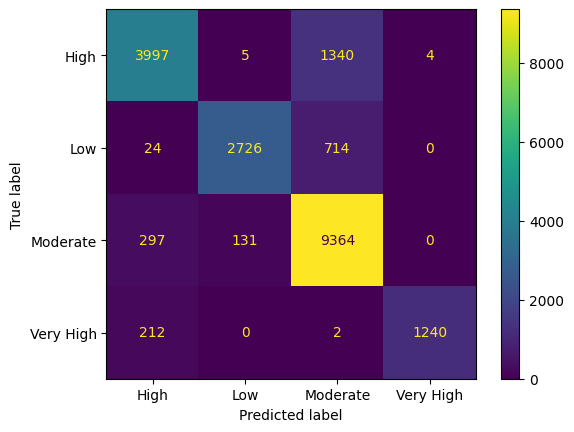

In [150]:
_ = ConfusionMatrixDisplay.from_predictions(y_test_tensor, test_predicted, display_labels=le.classes_)

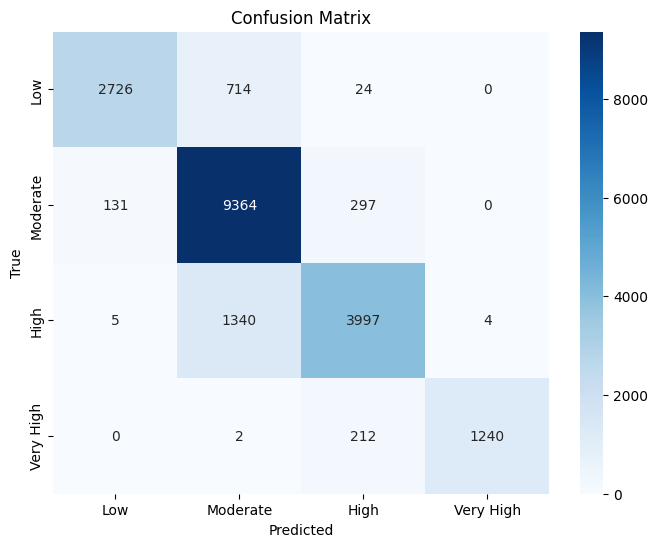

In [151]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

y_true = y_test_tensor.cpu().numpy()
y_pred = test_predicted.cpu().numpy()

desired_order = ["Low", "Moderate", "High", "Very High"]

y_true_str = le.inverse_transform(y_true)
y_pred_str = le.inverse_transform(y_pred)

cm = confusion_matrix(y_true_str, y_pred_str, labels=desired_order)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
            xticklabels=desired_order, yticklabels=desired_order)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

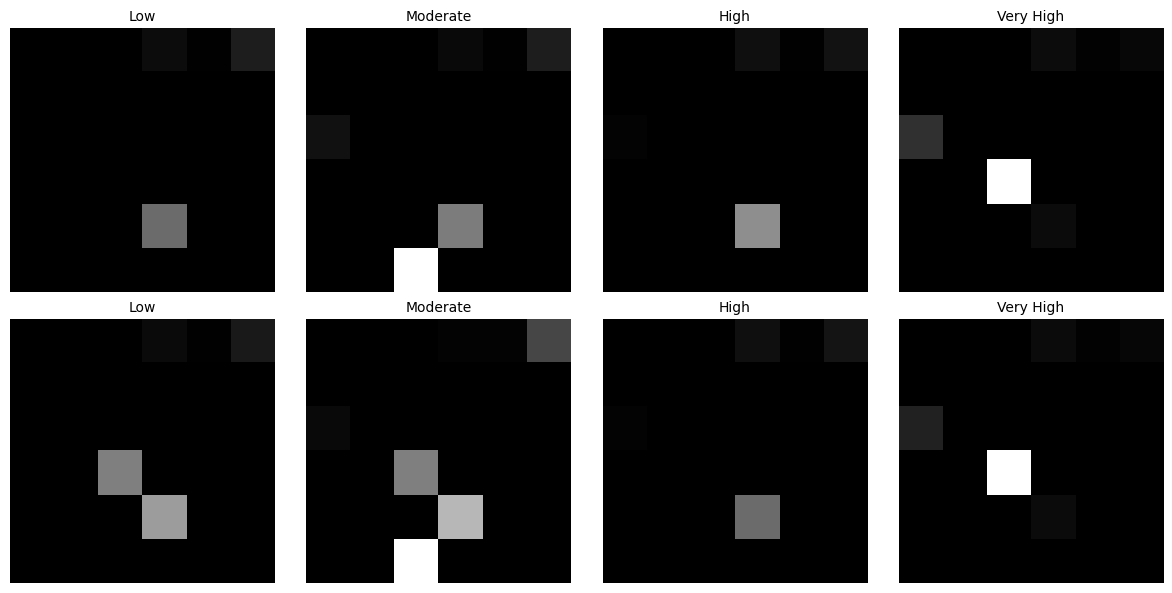

In [ ]:
import matplotlib.pyplot as plt
import random
import numpy as np

desired_order = ["Low", "Moderate", "High", "Very High"]

selected_indices = {}
for lbl in desired_order:
    indices = [i for i, category in enumerate(y_train) if category == lbl]
    if len(indices) >= 2:
        selected_indices[lbl] = random.sample(indices, 2)
    elif indices:
        selected_indices[lbl] = indices  
    else:
        print(f"No samples found for category: {lbl}")

ncols = len(selected_indices)
nrows = 2

fig, axs = plt.subplots(nrows, ncols, figsize=(ncols*3, nrows*3))

if ncols == 1:
    axs = np.array([axs]).reshape(nrows, ncols)

for col, lbl in enumerate(desired_order):
    if lbl in selected_indices:
        for row in range(nrows):
            try:
                idx = selected_indices[lbl][row]
            except IndexError:
                continue
            img = X_train_img[idx]
            if img.shape[0] == 1:
                img = np.squeeze(img, axis=0)
            axs[row, col].imshow(img)
            axs[row, col].set_title(f"{lbl}", fontsize=10)
            axs[row, col].axis("off")
    else:
        for row in range(nrows):
            axs[row, col].axis("off")

plt.tight_layout()
plt.show()